In [82]:
%pip install numpy matplotlib nbconvert pandadoc scipy lalsuite gwpy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import kalman
kalman.set_debug(0)

import kalman.chrono as chrono

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Linear Kalman Filter: Ballistic Projectile Model 1D

Chrono summary:
 1. Model initialized: 0.000008s (ΔT=0.000008s)
 2. Sampling completed: 0.086459s (ΔT=0.086451s)
 3. Filtering completed: 0.169807s (ΔT=0.083348s)
 4. Position plot completed: 0.190762s (ΔT=0.020955s)
 5. Speed plot completed: 0.203685s (ΔT=0.012923s)
 6. Acceleration plot completed: 0.216438s (ΔT=0.012753s)

==> Total elapsed: 0.230768s



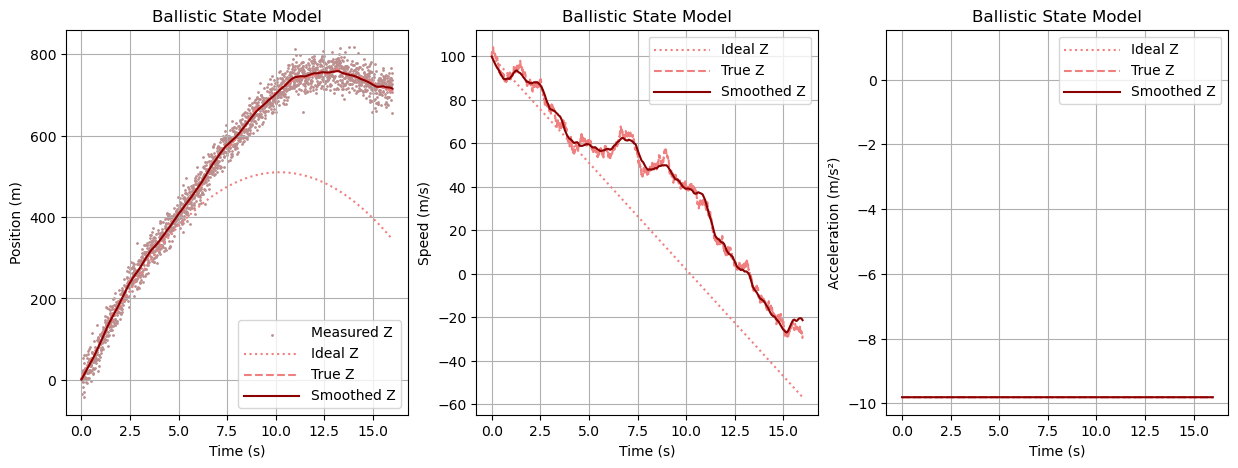

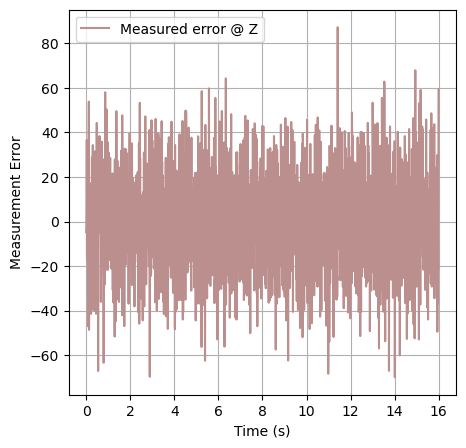

In [104]:
from kalman.models import BallisticStateModel

bulletbill = BallisticStateModel(dim=1, sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5)
bulletbill.initial_state([0, 100, -9.81]) # Initial state: [z, vz, az]
# bulletbill.print()

chrono.restart()
chrono.lap("Model initialized")
sample = bulletbill.sample(16)
chrono.lap("Sampling completed")
record = bulletbill.filter(sample, smooth=True, reset=True)
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)

record.plot(sample=sample, fig=canvas[0], component="position")
chrono.lap("Position plot completed")
record.plot(sample=sample, fig=canvas[1], component="speed")
chrono.lap("Speed plot completed")
record.plot(sample=sample, fig=canvas[2], component="acceleration")
chrono.lap("Acceleration plot completed")

record.plot_error(sample=sample)
chrono.summary()

## Linear Kalman Filter: Ballistic Projectile Model 3D

KalmanStateModel(fs = 128Hz):

    Ballistic State Model (v1.0)
        State model for ballistic trajectories, simulating
        the motion of a projectile under the
        influence of gravity with constant
        acceleration.

    Dimensions Summary:
        State Vector....................................: 9 dims
        Control Input...................................: 1 dim
        Observation.....................................: 3 dims

    Initial State:
        State Vector (x0)...............................: 9x1 dims
        State Covariance (P0)...........................: 9x9 dims

    Matrix Information:
        System Dynamics F (also known as A).............: 9x9 dims
        Observation Matrix H (also known as C)..........: 3x9 dims

        Control Input B (also known as U)...............: 9x1 dims
        Process Noise Covariance Q (also known as W)....: 9x9 dims
        Measurement Noise Covariance R (also known as V): 3x3 dims

KalmanStateRecord:

    Ballisti

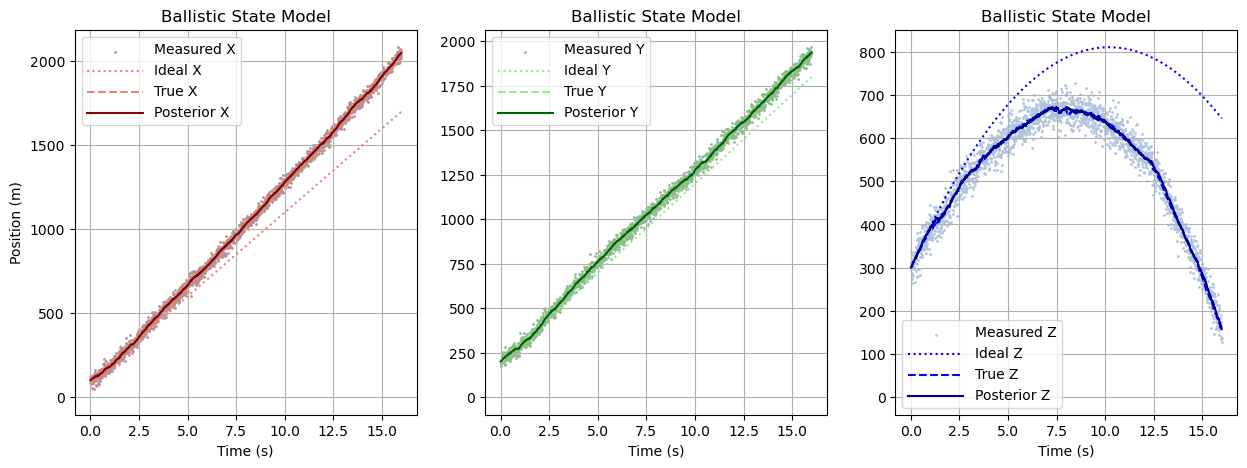

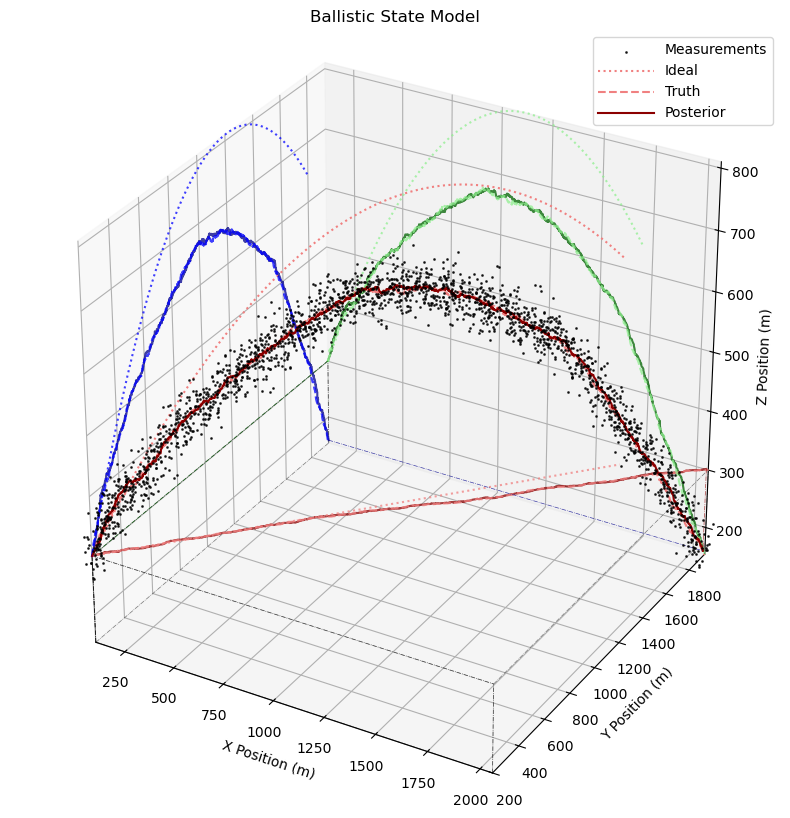

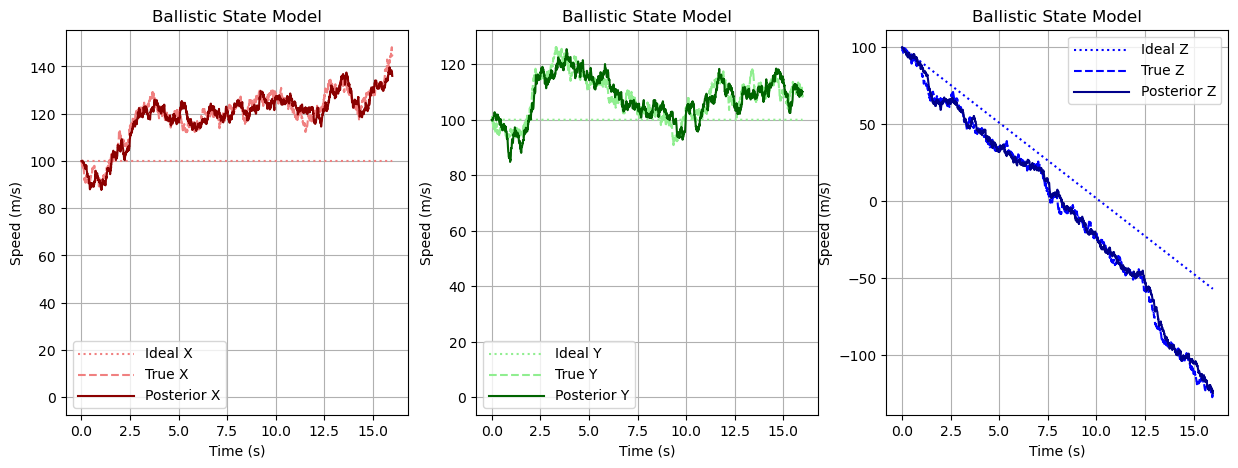

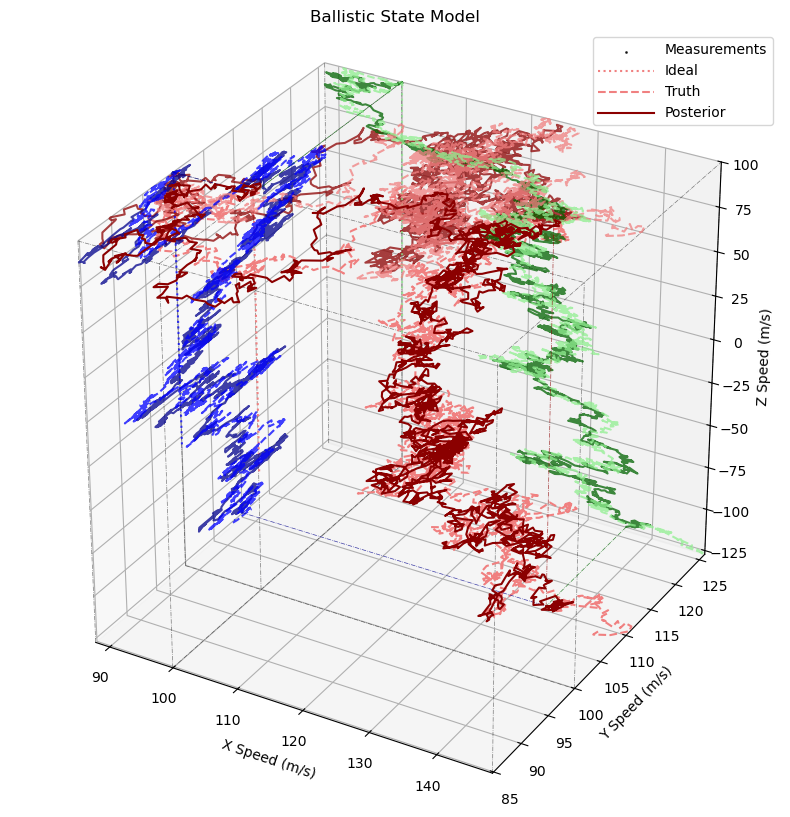

In [ ]:
chrono.restart()

from kalman.models import BallisticStateModel
bulletbill = BallisticStateModel(dim=3, sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42)
bulletbill.initial_state([
    [100, 100, 0],    # Initial state: [x, vx, ax] 
    [200, 100, 0],    # Initial state: [y, vy, ay]
    [300, 100, -9.81] # Initial state: [z, vz, az]
])
bulletbill.print()
chrono.lap("Model initialized")

sample = bulletbill.sample(16)
chrono.lap("Sampling completed")

record = bulletbill.filter(sample.zk, smooth=False, reset=True)
record.print()
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)
record.plot(sample=sample, component="position", dim=0, fig=canvas[0])
record.plot(sample=sample, component="position", dim=1, fig=canvas[1], sharey = True)
record.plot(sample=sample, component="position", dim=2, fig=canvas[2], sharey = True)
record.plot(sample=sample, component="position")
chrono.lap("Position plot completed")

canvas = get_canvas(3, 1)
record.plot(sample=sample, component="speed", dim=0, fig=canvas[0])
record.plot(sample=sample, component="speed", dim=1, fig=canvas[1])
record.plot(sample=sample, component="speed", dim=2, fig=canvas[2])
record.plot(sample=sample, component=["speed", "speed", "speed"])
chrono.lap("Speed plot completed")

chrono.summary()

## Power Grid 50/60Hz Model

## Violin Suspension Model